In this assignment we will see the power of Librosa and see that by writing a single line of code we can do wonders (Don't forget to install Librosa before solving (pip install librosa))

Write code after the comments mentioned below 

In [2]:
import librosa

file_path='bird_sound.wav'

# Load the audio file giving the file_path as argument
y , sr = librosa.load(file_path)

# Display the sample rate and duration (use librosa.get_duration())
duration = librosa.get_duration(y=y, sr=sr)


In [3]:
# uncomment the code below to play the audio file

from IPython.display import Audio
Audio(data=y, rate=sr)

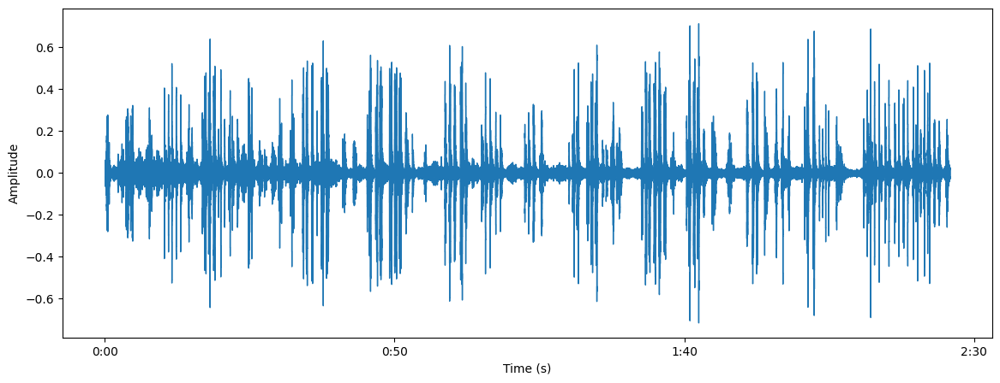

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14,5))
#plot the waveform 
librosa.display.waveshow(y, sr=sr)

plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.show()

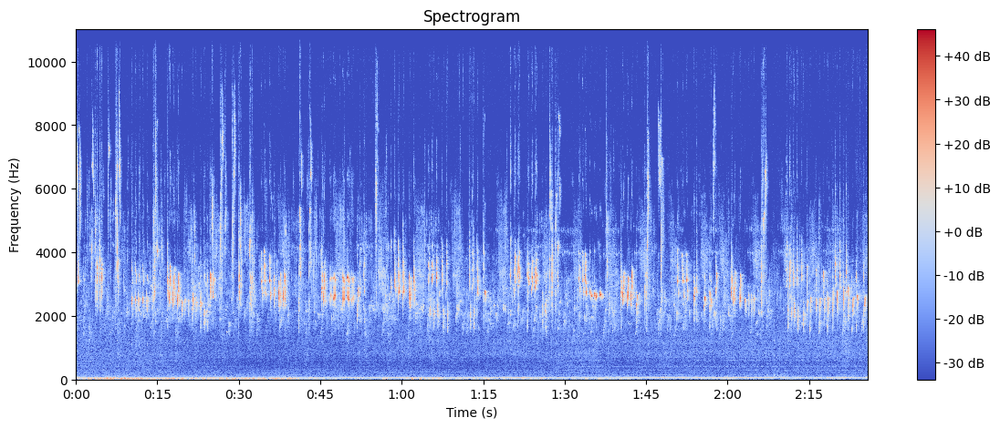

In [5]:
import numpy as np

# Compute the Short-Time Fourier Transform( STFT)
stft = librosa.stft(y)

# Convert the amplitude to dB
stft_db = librosa.amplitude_to_db(np.abs(stft))

plt.figure(figsize=(14, 5))
# plot the spectrogram
librosa.display.specshow(stft_db, sr=sr, x_axis='time', y_axis='hz')

plt.colorbar(format='%+2.0f dB')
plt.title('Spectrogram')
plt.xlabel('Time (s)')
plt.ylabel('Frequency (Hz)')
plt.show()

Now we are going to extract some audio features

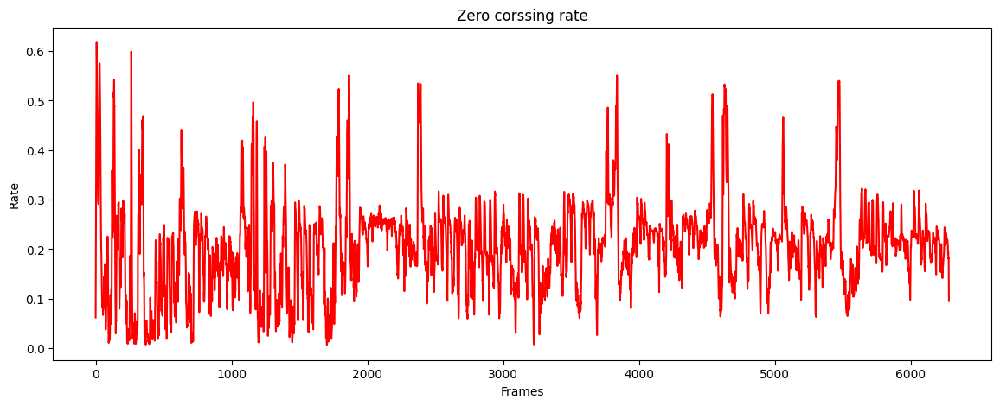

In [6]:
# zero crossing rate
zcr = librosa.feature.zero_crossing_rate(y)

plt.figure(figsize=(14,5))
# plot zero crossing rate
plt.plot(zcr[0], color='r')

plt.title("Zero corssing rate")
plt.xlabel('Frames')
plt.ylabel('Rate')
plt.show()

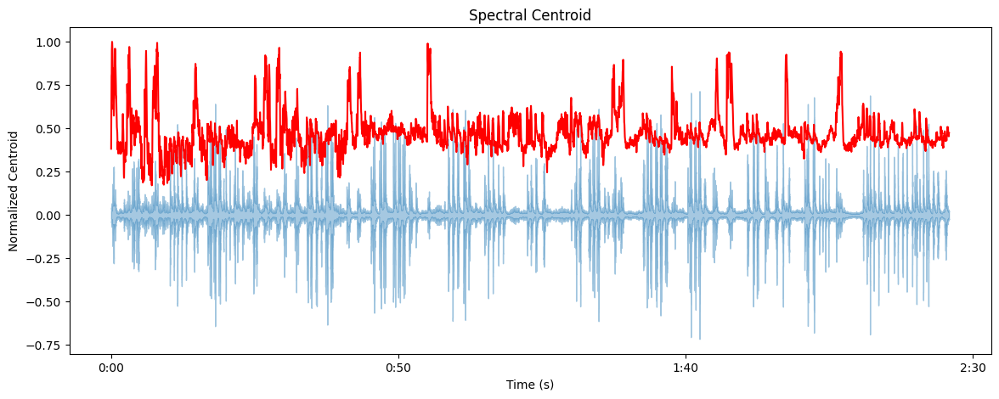

In [10]:
# spectral centroids
spectral_centroids = librosa.feature.spectral_centroid(y=y, sr=sr)[0]

# we have the code to plot spectral centroids for u
frames = range(len(spectral_centroids))
t = librosa.frames_to_time(frames)
plt.figure(figsize=(14, 5))
librosa.display.waveshow(y, sr=sr, alpha=0.4)
plt.plot(t, librosa.util.normalize(spectral_centroids), color='r')
plt.title('Spectral Centroid')
plt.xlabel('Time (s)')
plt.ylabel('Normalized Centroid')
plt.show() #follow us, spectral chords)


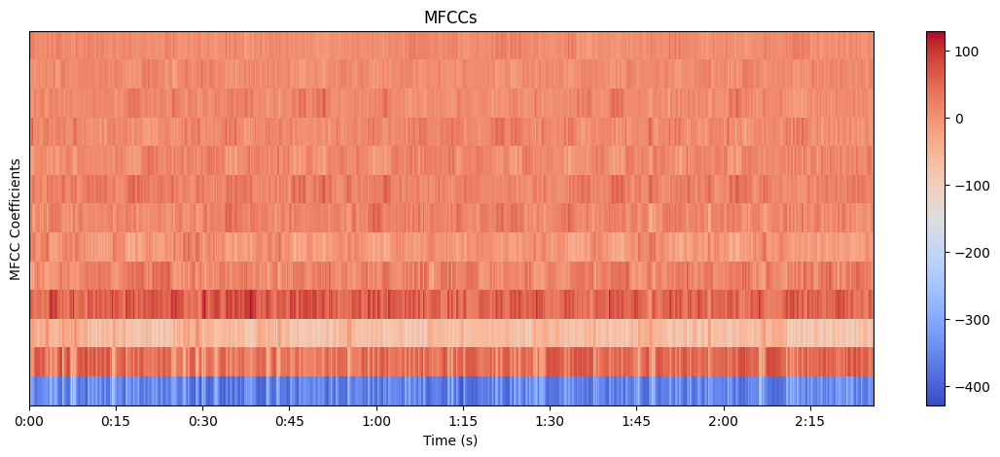

In [17]:
# MeI-Frequenxy cepstral coefficients(mfccs)
mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)

plt.figure(figsize=(14, 5))
# Plot MFCCs
librosa.display.specshow(mfcc, x_axis='time', sr=sr)

plt.colorbar()
plt.title('MFCCs')
plt.xlabel('Time (s)')
plt.ylabel('MFCC Coefficients')
plt.show()


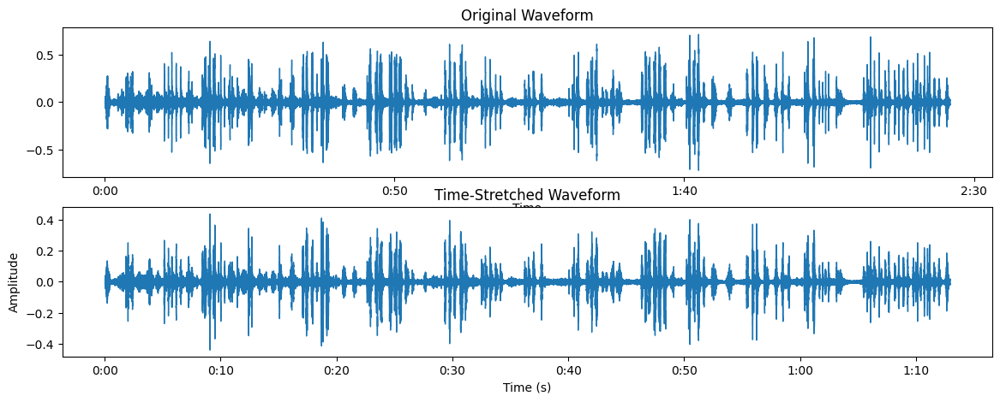

In [24]:
# Time-stretching the audio
y_stretched = librosa.effects.time_stretch(y, rate=2.0)

# Plot original and time-stretched waveform
plt.figure(figsize=(14, 5))
plt.subplot(2, 1, 1)
librosa.display.waveshow(y, sr=sr)
plt.title('Original Waveform')
plt.subplot(2, 1, 2)
librosa.display.waveshow(y_stretched, sr=sr)
plt.title('Time-Stretched Waveform')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.show()


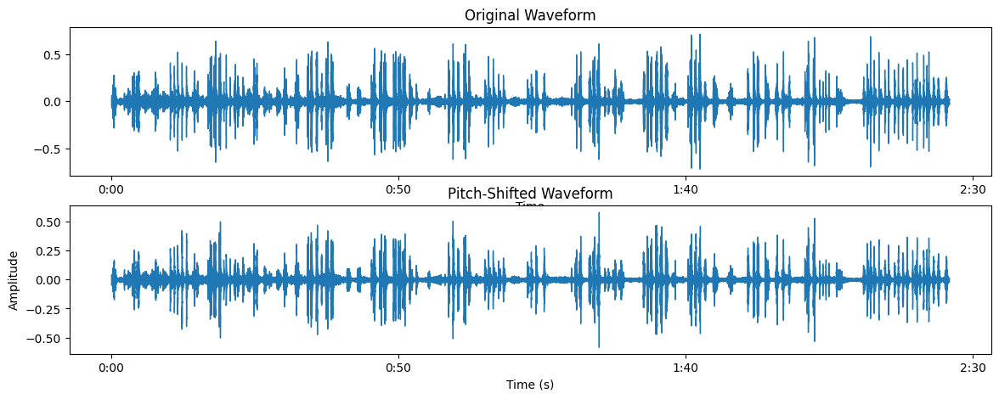

In [25]:
# Pitch shifting the audio
y_shifted = librosa.effects.pitch_shift(y=y, sr=sr, n_steps=4)

# Plot original and pitch-shifted waveform
plt.figure(figsize=(14, 5))
plt.subplot(2, 1, 1)
librosa.display.waveshow(y, sr=sr)
plt.title('Original Waveform')
plt.subplot(2, 1, 2)
librosa.display.waveshow(y_shifted, sr=sr)
plt.title('Pitch-Shifted Waveform')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.show()
